# 1. Basic

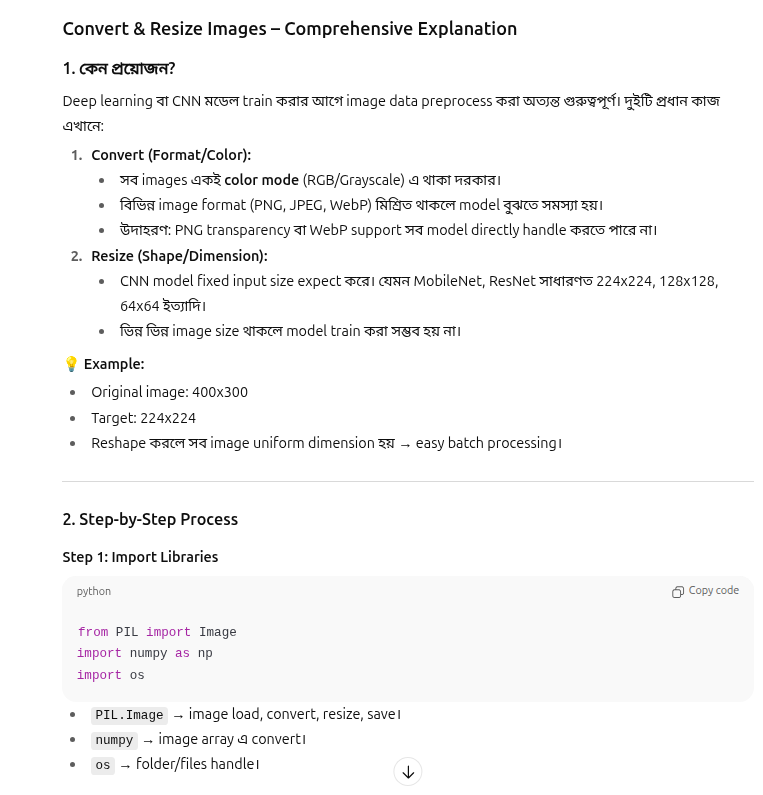

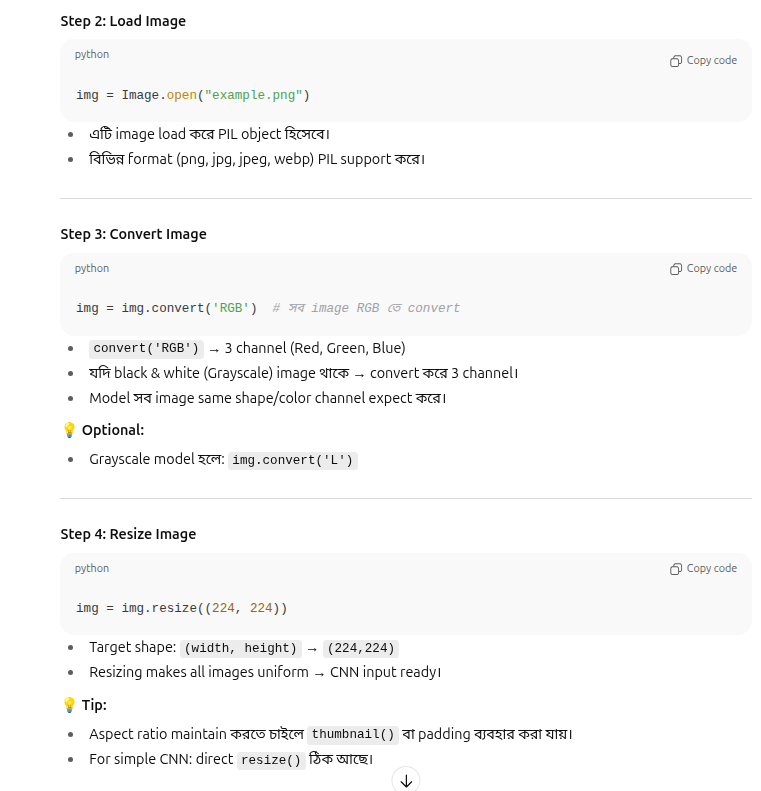

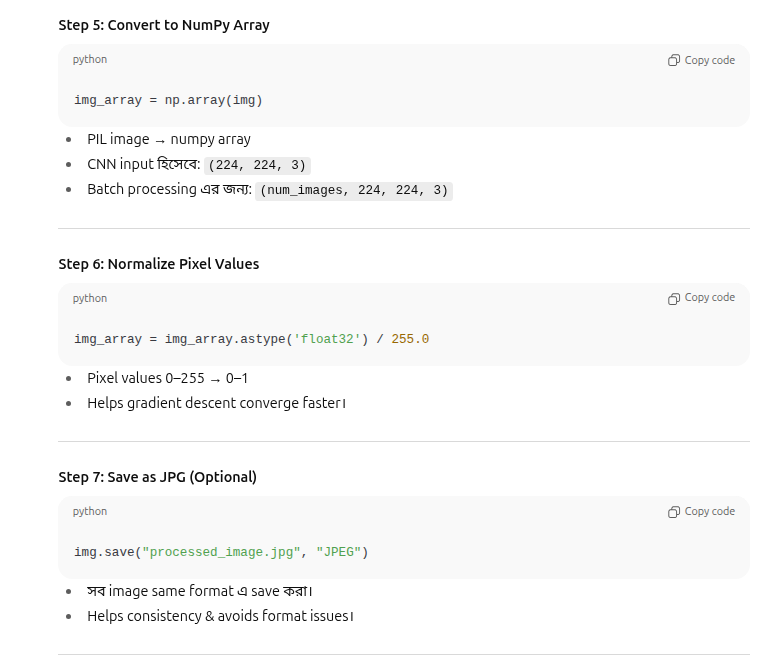

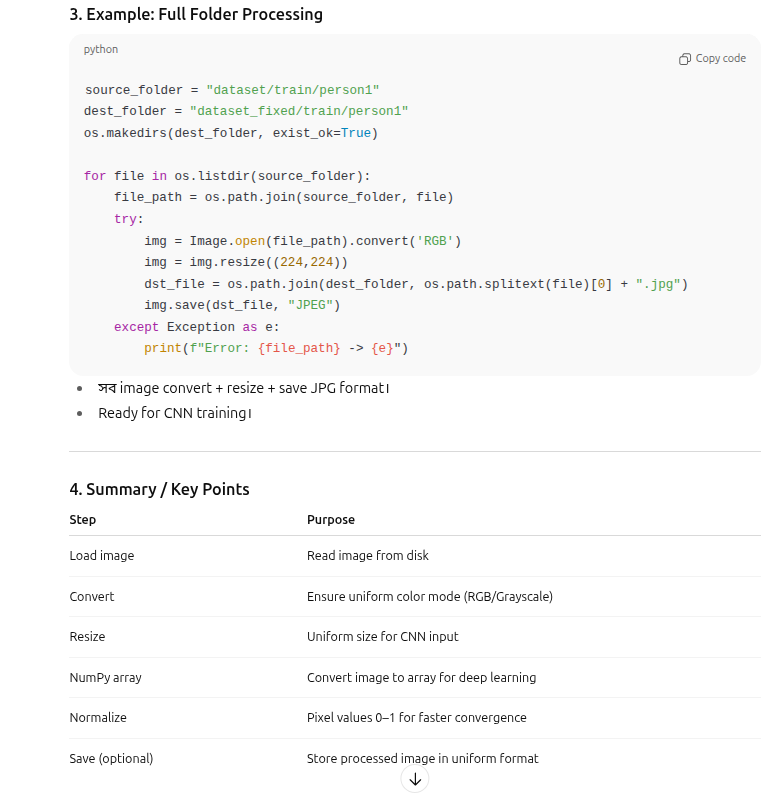

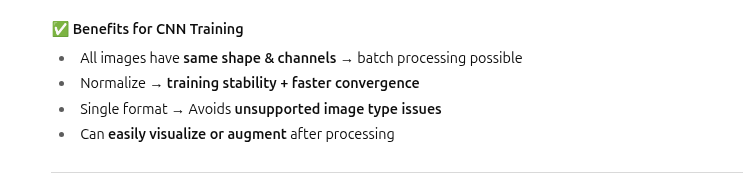

**More**

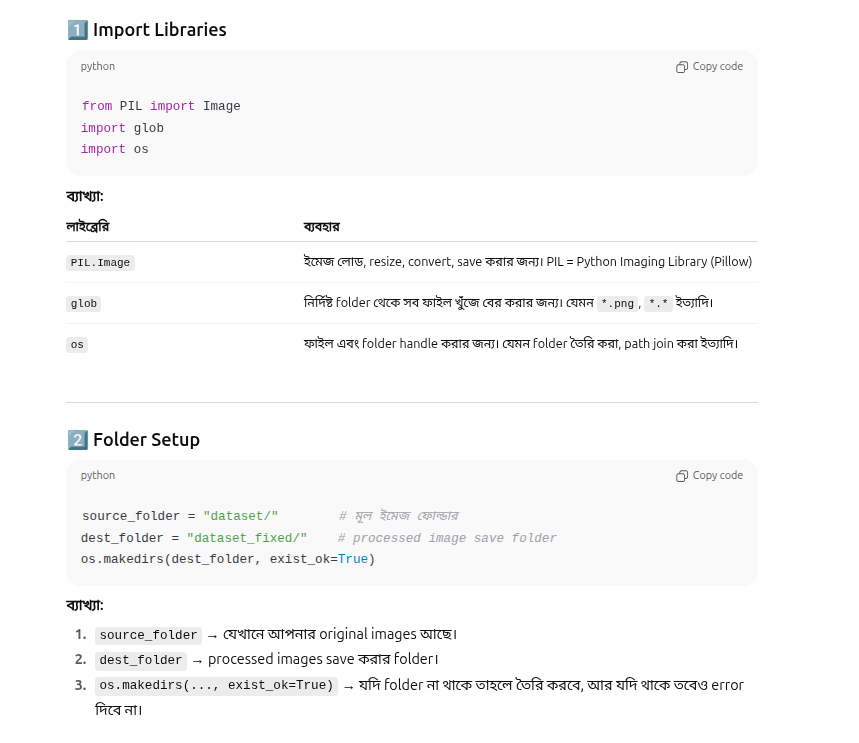

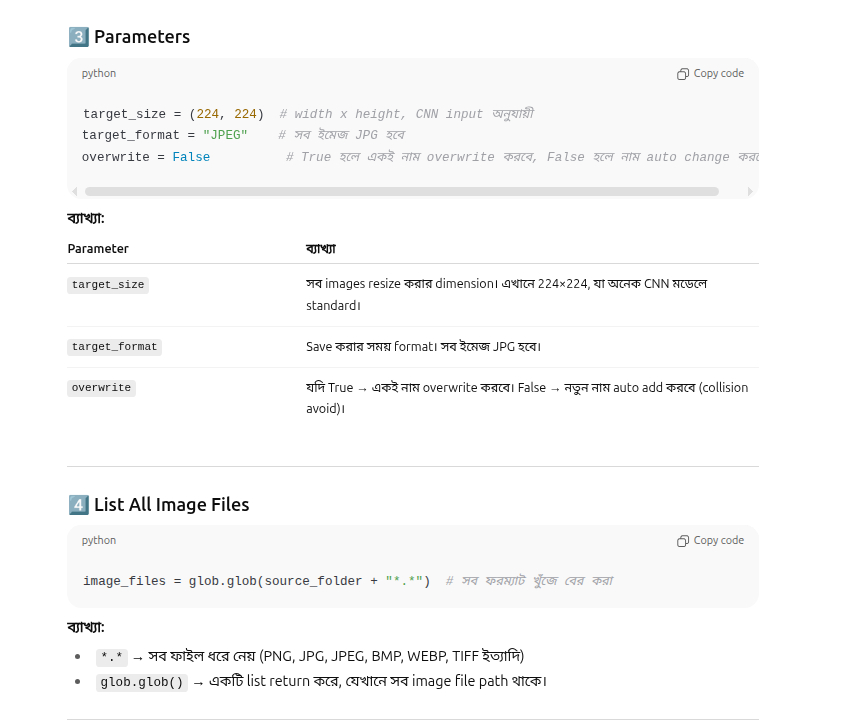

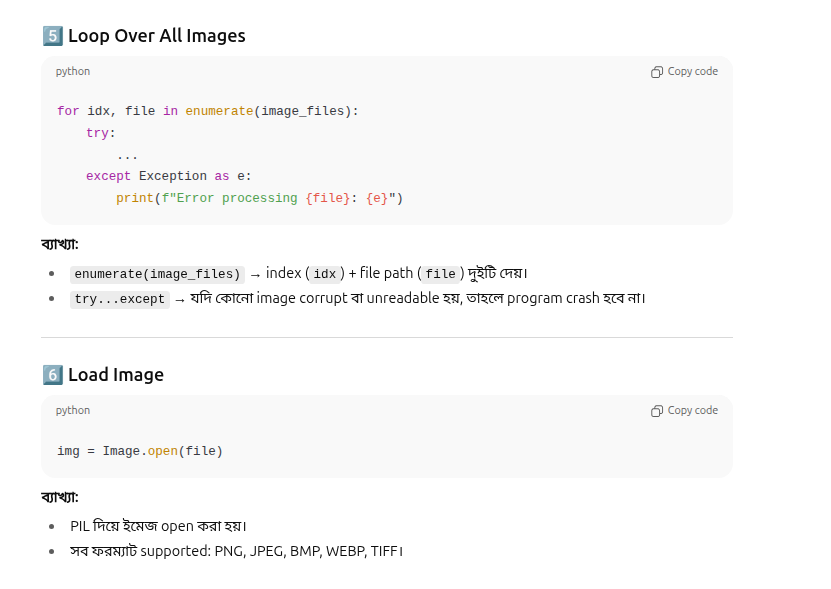

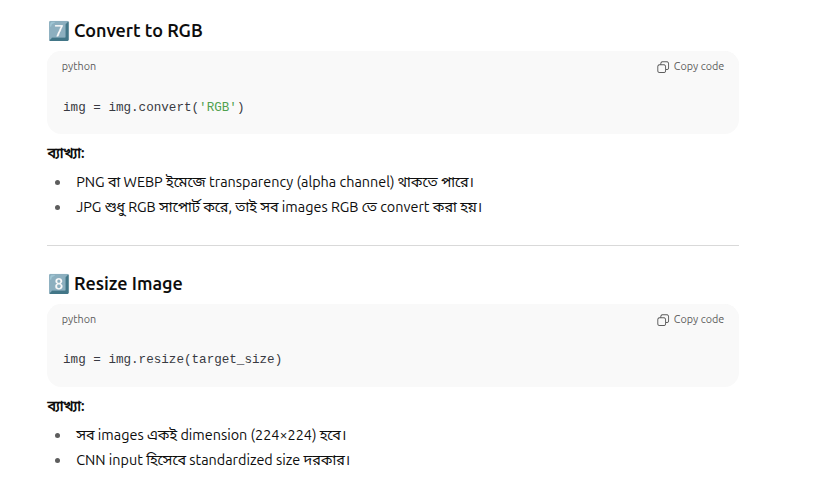

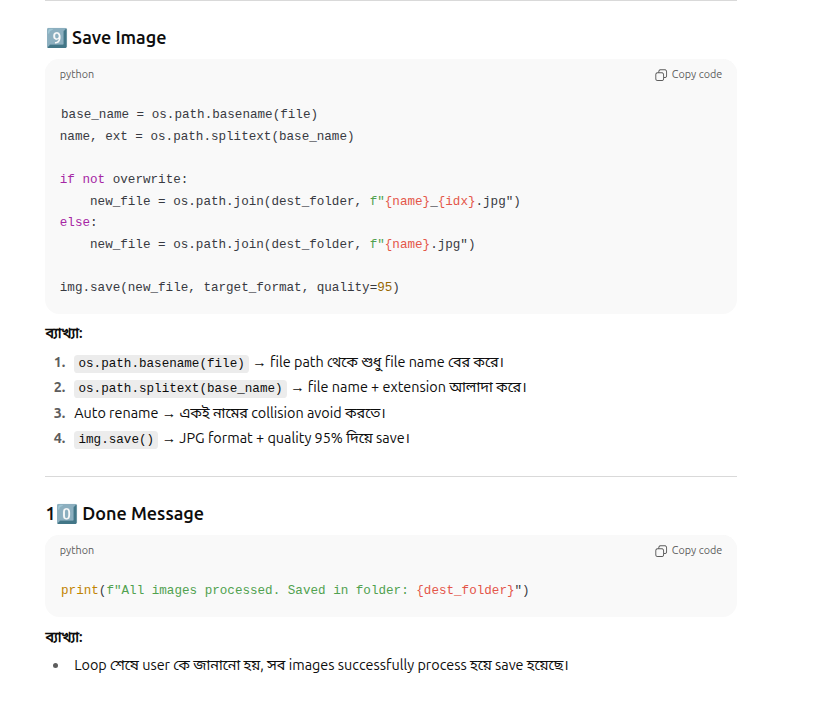

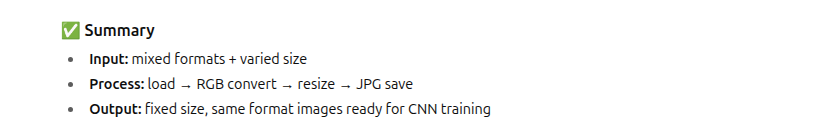

# 2. Folder Load (Total images, size)

In [5]:
import os
import numpy as np
from PIL import Image
from tensorflow.keras.utils import to_categorical

In [6]:
dataset_path = "dataset/train"  # path to your train folder
image_size = (224, 224)         # resize all images to 224x224

In [7]:
images = []
labels = []

# Get list of all person folders
person_folders = os.listdir(dataset_path)
person_folders.sort()  # optional, keep order consistent

for label, person_name in enumerate(person_folders):
    person_folder_path = os.path.join(dataset_path, person_name)
    
    # Loop over all images in the folder
    for file in os.listdir(person_folder_path):
        file_path = os.path.join(person_folder_path, file)
        try:
            # Open, resize, convert to array
            img = Image.open(file_path).convert('RGB')
            img = img.resize(image_size)
            img_array = np.array(img)
            
            images.append(img_array)
            labels.append(label)
        except Exception as e:
            print(f"Error loading {file_path}: {e}")

# Convert to numpy arrays
images = np.array(images, dtype='float32') / 255.0  # normalize 0-1
labels = np.array(labels)

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: (152, 224, 224, 3)
Labels shape: (152,)


# 3. Total folder / Persons

In [10]:
import os

dataset_path = "dataset/train"

# সব folder list
person_folders = os.listdir(dataset_path)

# শুধু folder সংখ্যা গণনা
total_folders = len(person_folders)

print("Total folders / persons:", total_folders)

Total folders / persons: 30


# 4. Print all folder / persons name

In [14]:
import os

dataset_path = "dataset/train"

# সব folder list
person_folders = os.listdir(dataset_path)
person_folders.sort()  # alphabetical order (optional)

# list আকারে print করা
print(person_folders)

['aqidi', 'bale', 'brozovic', 'bruyne', 'cancelo', 'casimiro', 'costa', 'cummins', 'deligt', 'dias', 'fernandes', 'gordon', 'haaland', 'kohli', 'mane', 'marcelo', 'mbappe', 'mendes', 'messi', 'ozil', 'pepe', 'pickford', 'ramos', 'rodriguez', 'ronaldo', 'saka', 'shelton', 'sinner', 'trent', 'vitinha']


In [11]:
import os

dataset_path = "dataset/train"

# সব folder name list এ নেওয়া
person_folders = os.listdir(dataset_path)
person_folders.sort()  # alphabetical order এ arrange করা (optional)

print("All folders / person names:")
for folder in person_folders:
    print(folder)

All folders / person names:
aqidi
bale
brozovic
bruyne
cancelo
casimiro
costa
cummins
deligt
dias
fernandes
gordon
haaland
kohli
mane
marcelo
mbappe
mendes
messi
ozil
pepe
pickford
ramos
rodriguez
ronaldo
saka
shelton
sinner
trent
vitinha


In [28]:
import os

# Dataset folder path
dataset_path = "dataset/train"

# সব folder list
person_folders = os.listdir(dataset_path)
person_folders.sort()  # alphabetical order

# Folder name → label mapping
folder_label_map = {name: idx for idx, name in enumerate(person_folders)}

# Print dictionary nicely
import pprint
pprint.pprint(folder_label_map)

{'aqidi': 0,
 'bale': 1,
 'brozovic': 2,
 'bruyne': 3,
 'cancelo': 4,
 'casimiro': 5,
 'costa': 6,
 'cummins': 7,
 'deligt': 8,
 'dias': 9,
 'fernandes': 10,
 'gordon': 11,
 'haaland': 12,
 'kohli': 13,
 'mane': 14,
 'marcelo': 15,
 'mbappe': 16,
 'mendes': 17,
 'messi': 18,
 'ozil': 19,
 'pepe': 20,
 'pickford': 21,
 'ramos': 22,
 'rodriguez': 23,
 'ronaldo': 24,
 'saka': 25,
 'shelton': 26,
 'sinner': 27,
 'trent': 28,
 'vitinha': 29}


# 5. Print specific folder all images

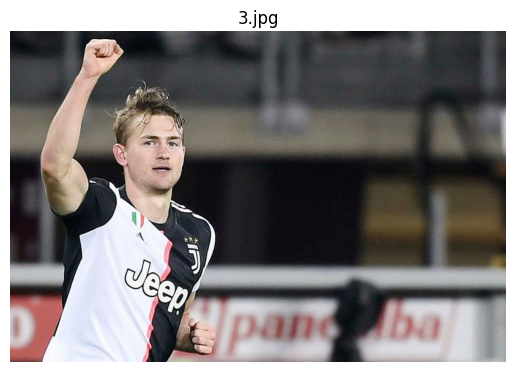

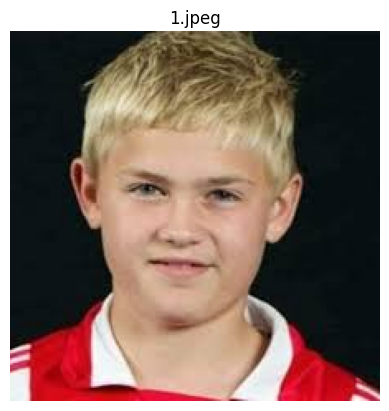

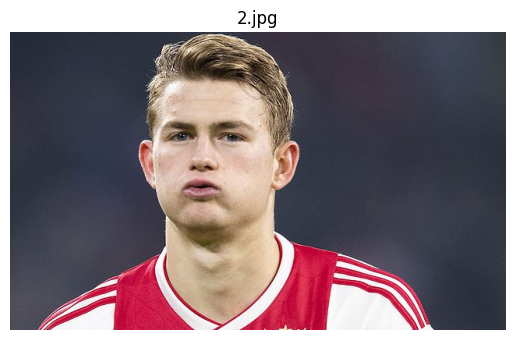

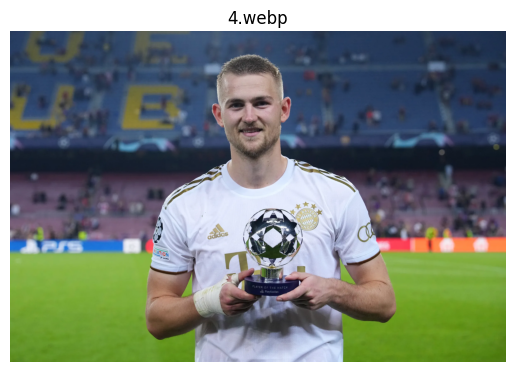

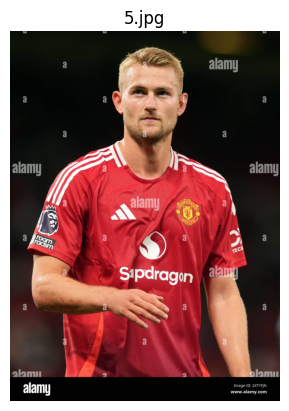

In [15]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Folder path (যেখানে images আছে)
folder_name = "deligt"
folder_path = os.path.join("dataset/train", folder_name)

# সব image file list
image_files = os.listdir(folder_path)

# Loop করে সব image display করা
for file in image_files:
    file_path = os.path.join(folder_path, file)
    try:
        img = Image.open(file_path).convert('RGB')  # RGB তে convert
        plt.imshow(img)
        plt.title(file)  # image file নাম title হিসেবে
        plt.axis('off')
        plt.show()
    except Exception as e:
        print(f"Error loading {file_path}: {e}")

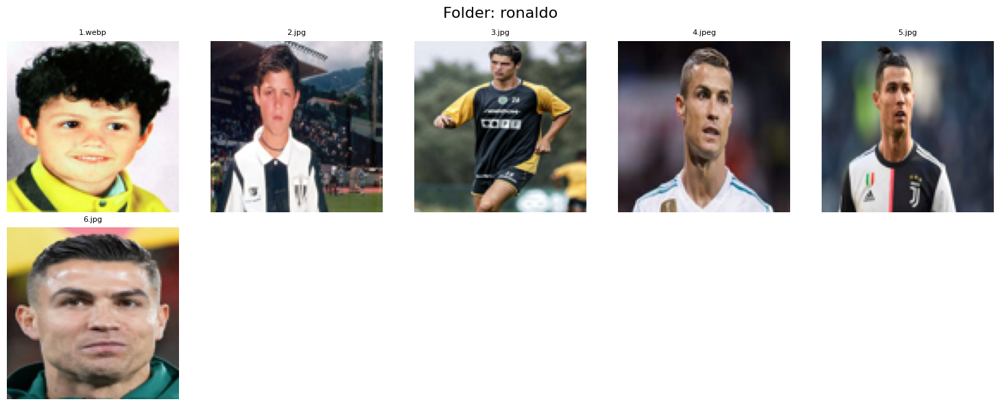

In [27]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import math

# -------------------------------
# Parameters
# -------------------------------
folder_name = "ronaldo"               # যেই folder এর images দেখতে চাও
folder_path = os.path.join("dataset/train", folder_name)
cols = 5                             # প্রতি row এ 5 image
image_size = (100, 100)              # grid view এ ছোট image size

# -------------------------------
# Get all images in the folder
# -------------------------------
image_files = os.listdir(folder_path)
image_files.sort()
total_images = len(image_files)
rows = math.ceil(total_images / cols)

plt.figure(figsize=(cols*3, rows*3))
plt.suptitle(f"Folder: {folder_name}", fontsize=16)

# -------------------------------
# Loop over images
# -------------------------------
for idx, file in enumerate(image_files):
    file_path = os.path.join(folder_path, file)
    try:
        img = Image.open(file_path).convert('RGB')
        img = img.resize(image_size)
        
        plt.subplot(rows, cols, idx+1)
        plt.imshow(img)
        plt.title(file, fontsize=8)
        plt.axis('off')
    except Exception as e:
        print(f"Error loading {file_path}: {e}")

plt.tight_layout()
plt.show()

# 6. Convert all images to JPG + resize + save in new folder

In [20]:
import os
from PIL import Image
import numpy as np

# -------------------------------
# Parameters
# -------------------------------
source_path = "dataset/train"           # মূল train folder
dest_path = "dataset_fixed/train"       # processed images save folder
image_size = (224, 224)                 # reshape size

os.makedirs(dest_path, exist_ok=True)   # নতুন folder create

# -------------------------------
# Process each folder
# -------------------------------
person_folders = os.listdir(source_path)
person_folders.sort()  # optional

for folder_name in person_folders:
    src_folder = os.path.join(source_path, folder_name)
    dst_folder = os.path.join(dest_path, folder_name)
    os.makedirs(dst_folder, exist_ok=True)  # create folder in new location
    
    for file in os.listdir(src_folder):
        src_file = os.path.join(src_folder, file)
        try:
            img = Image.open(src_file).convert('RGB')  # সব image RGB তে convert
            img = img.resize(image_size)               # reshape
            
            # Save as JPG
            filename = os.path.splitext(file)[0] + ".jpg"  # convert name to .jpg
            dst_file = os.path.join(dst_folder, filename)
            img.save(dst_file, "JPEG")
            
        except Exception as e:
            print(f"Error processing {src_file}: {e}")

print("All images converted, resized, and saved in:", dest_path)

All images converted, resized, and saved in: dataset_fixed/train


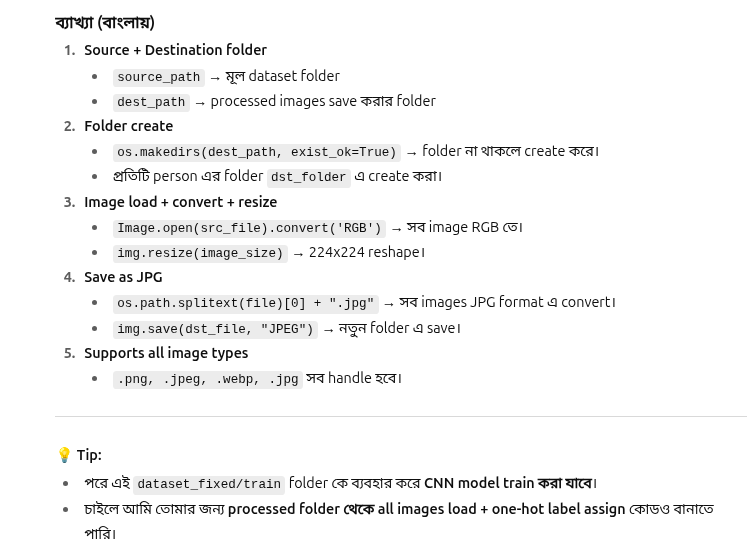

**All images**

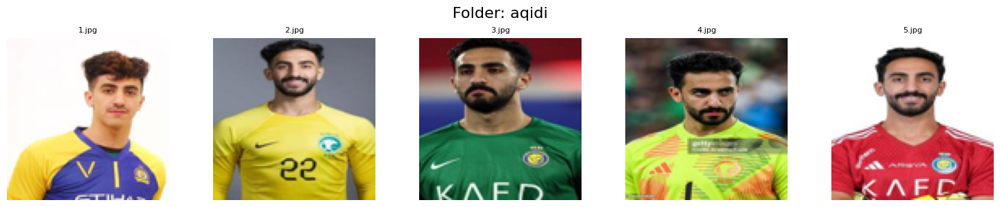

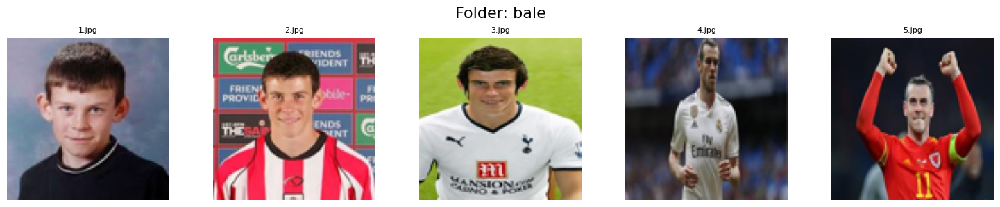

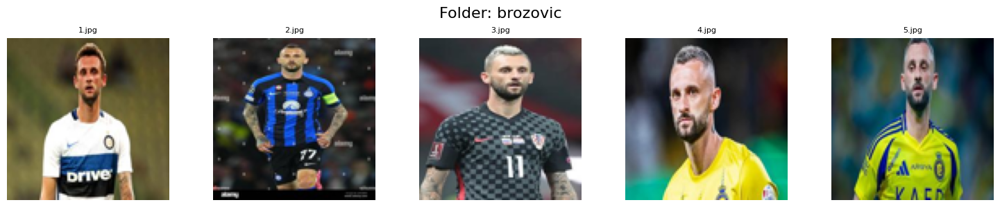

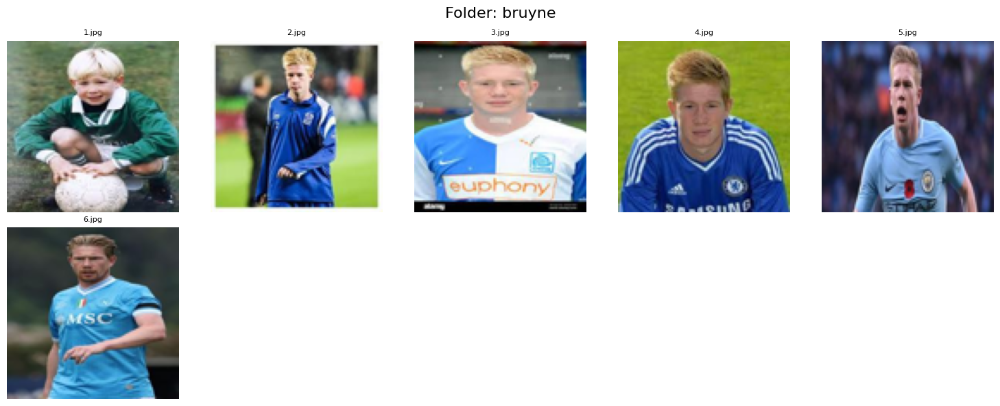

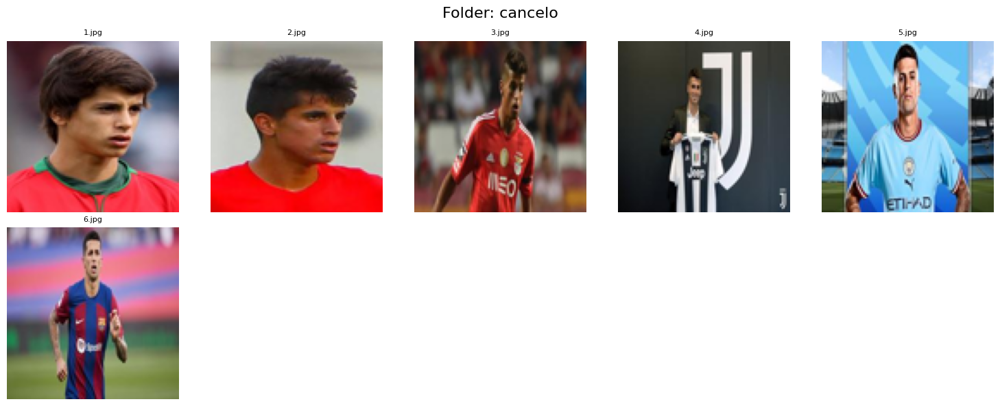

...

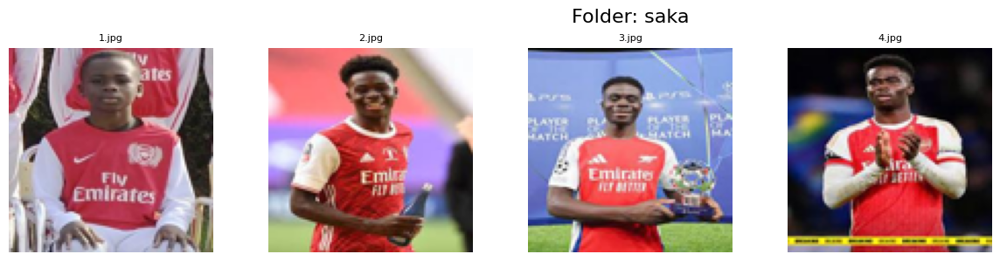

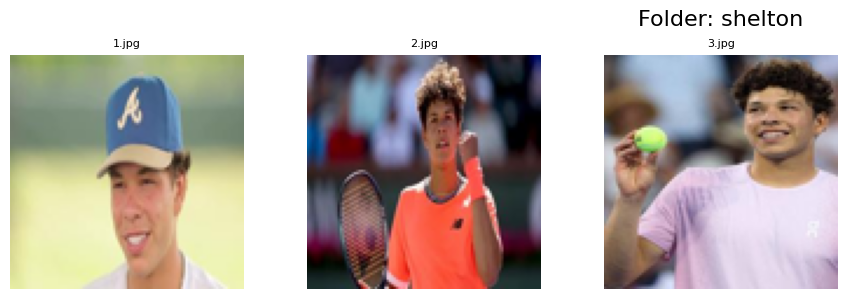

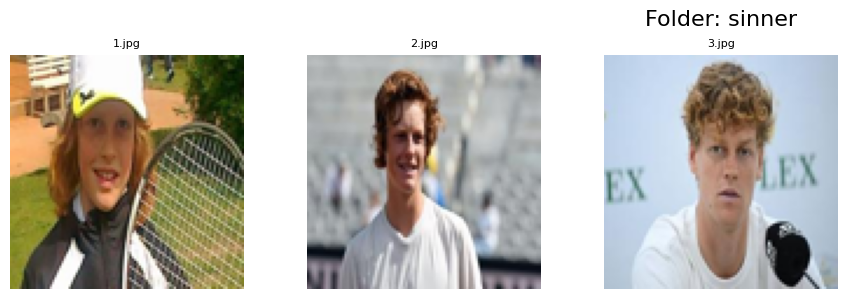

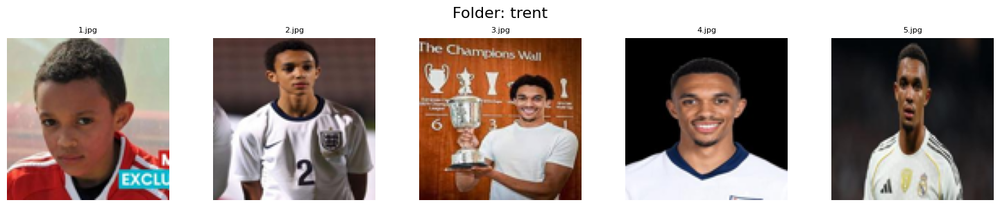

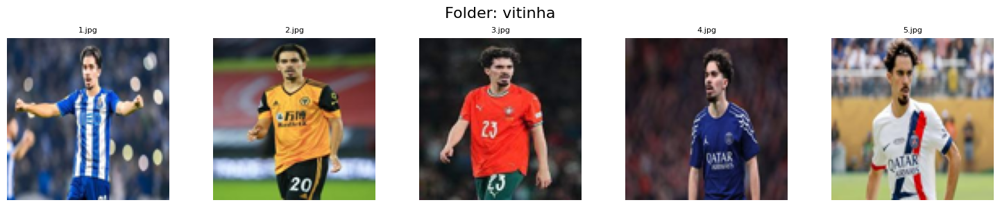

In [25]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import math

# -------------------------------
# Parameters
# -------------------------------
dataset_path = "dataset_fixed/train/"
cols = 5            # প্রতি row এ কতটা image
image_size = (100, 100)  # grid এ দেখানোর জন্য ছোট size

# -------------------------------
# Get all folder names
# -------------------------------
person_folders = os.listdir(dataset_path)
person_folders.sort()  # optional

# -------------------------------
# Loop over all folders
# -------------------------------
for folder_name in person_folders:
    folder_path = os.path.join(dataset_path, folder_name)
    image_files = os.listdir(folder_path)
    image_files.sort()
    
    total_images = len(image_files)
    rows = math.ceil(total_images / cols)
    
    plt.figure(figsize=(cols*3, rows*3))
    plt.suptitle(f"Folder: {folder_name}", fontsize=16)
    
    for idx, file in enumerate(image_files):
        file_path = os.path.join(folder_path, file)
        try:
            img = Image.open(file_path).convert('RGB')
            img = img.resize(image_size)
            
            plt.subplot(rows, cols, idx+1)
            plt.imshow(img)
            plt.title(file, fontsize=8)
            plt.axis('off')
        except Exception as e:
            print(f"Error loading {file_path}: {e}")
    
    plt.tight_layout()
    plt.show()

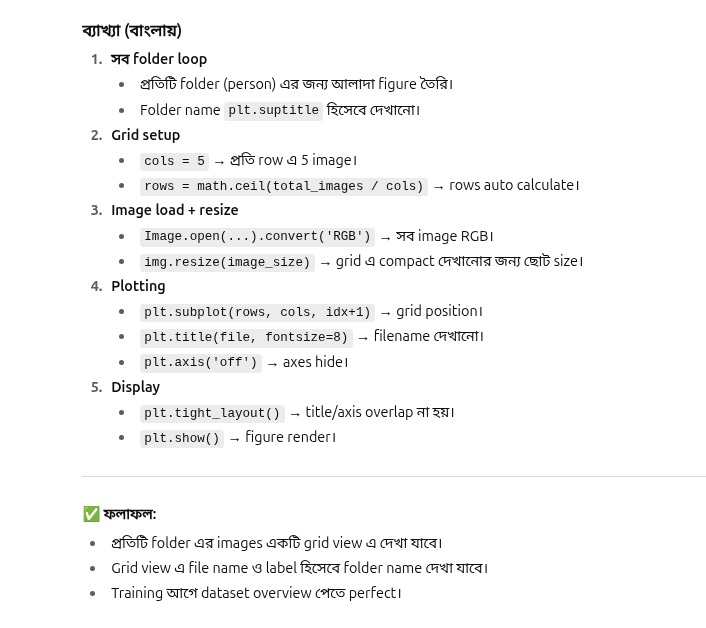

**Specific folder**

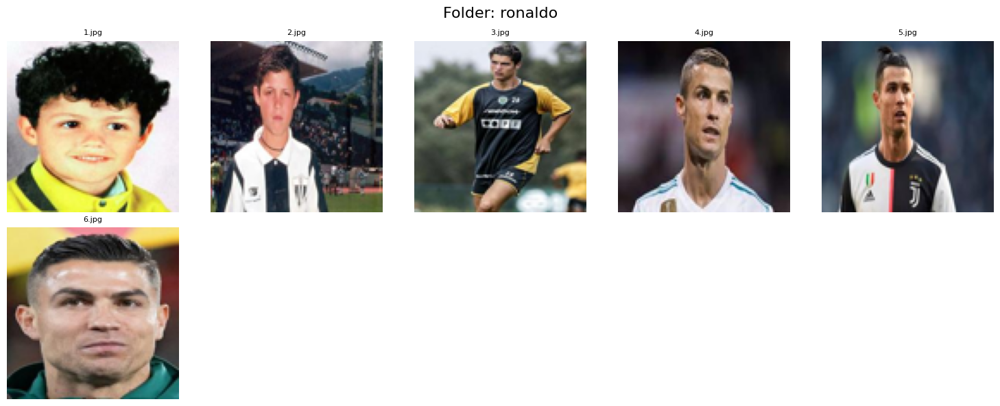

In [26]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import math

# -------------------------------
# Parameters
# -------------------------------
folder_name = "ronaldo"               # যেই folder এর images দেখতে চাও
folder_path = os.path.join("dataset_fixed/train", folder_name)
cols = 5                             # প্রতি row এ 5 image
image_size = (100, 100)              # grid view এ ছোট image size

# -------------------------------
# Get all images in the folder
# -------------------------------
image_files = os.listdir(folder_path)
image_files.sort()
total_images = len(image_files)
rows = math.ceil(total_images / cols)

plt.figure(figsize=(cols*3, rows*3))
plt.suptitle(f"Folder: {folder_name}", fontsize=16)

# -------------------------------
# Loop over images
# -------------------------------
for idx, file in enumerate(image_files):
    file_path = os.path.join(folder_path, file)
    try:
        img = Image.open(file_path).convert('RGB')
        img = img.resize(image_size)
        
        plt.subplot(rows, cols, idx+1)
        plt.imshow(img)
        plt.title(file, fontsize=8)
        plt.axis('off')
    except Exception as e:
        print(f"Error loading {file_path}: {e}")

plt.tight_layout()
plt.show()

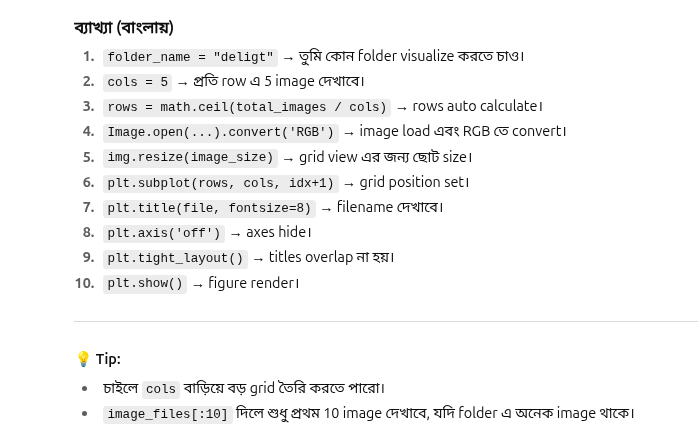